# Stage 1: Understand, check, prepare and explore retail sales

**Goal:** Understand the complete dataset before training a model. Later we will forecast daily **Units Sold** for a selected store and product, then calculate additional stock.

Roman Urdu: Pehle data samjhein, uski quality check karein aur charts dekhein. Har cell upar se neeche run karein.

This is publisher-generated synthetic practice data, not verified real retail transactions. The included source copy was retrieved on 21 October 2026. It is already provided, so no Kaggle login is needed to run this notebook.

Source: https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset

This stage does not train models. Its outputs will be used by the later chronological modelling notebook.

## 1. Import libraries and find the project folder

`pandas` reads tables. `matplotlib` draws charts. `Path` handles file paths on Windows and Linux.
The notebook works from the project root or the `notebooks` folder.

In [2]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project = Path.cwd()
if not (project / "data/raw/retail_store_inventory.csv").exists():
    project = project.parent

raw_path = project / "data/raw/retail_store_inventory.csv"
assert raw_path.exists(), "Open this notebook from the project or notebooks folder."
figures = project / "reports/figures"
audit_folder = project / "reports/audit"
figures.mkdir(parents=True, exist_ok=True)
audit_folder.mkdir(parents=True, exist_ok=True)
plt.style.use("ggplot")
print("Dataset:", raw_path.name)

Dataset: retail_store_inventory.csv


## 2. Read the original dataset

`raw` preserves the loaded data. We will clean a separate copy. `head()` shows the first five rows; `shape` shows the number of rows and columns.

In [3]:
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
raw = pd.read_csv(raw_path)
print("Rows and columns:", raw.shape)
print(raw.head().to_string(index=False))

Rows and columns: (73100, 15)
      Date Store ID Product ID    Category Region  Inventory Level  Units Sold  Units Ordered  Demand Forecast  Price  Discount Weather Condition  Holiday/Promotion  Competitor Pricing Seasonality
2022-01-01     S001      P0001   Groceries  North              231         127             55           135.47  33.50        20             Rainy                  0               29.69      Autumn
2022-01-01     S001      P0002        Toys  South              204         150             66           144.04  63.01        20             Sunny                  0               66.16      Autumn
2022-01-01     S001      P0003        Toys   West              102          65             51            74.02  27.99        10             Sunny                  1               31.32      Summer
2022-01-01     S001      P0004        Toys  North              469          61            164            62.18  32.72        10            Cloudy                  1               34.

## 3. Understand the columns

| Column | Meaning and role |
|---|---|
| Date | Day of the observation |
| Store ID / Product ID | Identify one store-product sales history |
| Units Sold | Target to forecast |
| Inventory Level | Publisher describes this as beginning-of-day inventory |
| Units Ordered | Historical replenishment record; not automatically future incoming stock |
| Demand Forecast | Publisher-supplied estimate with an unverified generation process; exclude as a predictor |
| Price / Discount / Competitor Pricing | Possible explanatory variables; future availability must be established |
| Weather Condition / Holiday/Promotion / Seasonality | Context; must not use unknown future information |
| Category / Region | Dataset labels whose consistency must be checked |

Roman Urdu: Har column model mein dalna zaroori nahi. Future mein jo information available na ho, usay future prediction ke liye input nahi bana sakte.

In [4]:
column_summary = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique()
})
print(column_summary.to_string())
column_summary.to_csv(audit_folder / "column_summary.csv", index_label="column")

                       type  missing  unique_values
Date                 object        0            731
Store ID             object        0              5
Product ID           object        0             20
Category             object        0              5
Region               object        0              4
Inventory Level       int64        0            451
Units Sold            int64        0            498
Units Ordered         int64        0            181
Demand Forecast     float64        0          31608
Price               float64        0           8999
Discount              int64        0              5
Weather Condition    object        0              4
Holiday/Promotion     int64        0              2
Competitor Pricing  float64        0           9751
Seasonality          object        0              4


## 4. Check duplicates, missing values and invalid values

We check all columns for missingness, and validate the essential fields separately.
Invalid essential rows are saved for review and stop this notebook. They are not silently filled or removed.
Exact duplicate rows can be removed, but conflicting records for the same store-product-date need investigation.

In [5]:
required = ["Date", "Store ID", "Product ID", "Units Sold", "Inventory Level"]
assert set(required).issubset(raw.columns), "A required column is missing."
duplicate_count = int(raw.duplicated().sum())
clean = raw.drop_duplicates().copy()
clean["Date"] = pd.to_datetime(clean["Date"], format="%Y-%m-%d", errors="coerce")
for column in ["Units Sold", "Inventory Level"]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")

invalid = clean[required].isna().any(axis=1)
invalid = invalid | (~np.isfinite(clean[["Units Sold", "Inventory Level"]])).any(axis=1)
invalid = invalid | (clean[["Units Sold", "Inventory Level"]] < 0).any(axis=1)
for column in ["Store ID", "Product ID"]:
    invalid = invalid | clean[column].astype(str).str.strip().eq("")

clean.loc[invalid].to_csv(audit_folder / "invalid_rows.csv", index=False)
print("Exact duplicate rows:", duplicate_count)
print("Missing cells in original data:", int(raw.isna().sum().sum()))
print("Rows with invalid essential values:", int(invalid.sum()))
assert not invalid.any(), "Review reports/audit/invalid_rows.csv before continuing."

keys = ["Store ID", "Product ID", "Date"]
conflicts = clean.duplicated(keys, keep=False)
clean.loc[conflicts].to_csv(audit_folder / "conflicting_rows.csv", index=False)
assert not conflicts.any(), "Resolve conflicting store-product-date records first."
assert clean["Date"].eq(clean["Date"].dt.normalize()).all(), "Daily dates must not contain times."

Exact duplicate rows: 0
Missing cells in original data: 0
Rows with invalid essential values: 0


## 5. Prepare daily sales histories and check missing dates

Sort by store, product and date. A zero sale is an observation; a missing date is an absent observation. We must not treat these as the same thing.
No scaling or encoding is applied here. Those decisions depend on the model and, when fitted, must use training data only.

In [15]:
clean = clean.sort_values(keys).reset_index(drop=True)
series_summary = clean.groupby(["Store ID", "Product ID"])["Date"].agg(["min", "max", "size"])
series_summary["missing_days"] = (series_summary["max"] - series_summary["min"]).dt.days + 1 - series_summary["size"]
series_summary.to_csv(audit_folder / "series_summary.csv")
print("Stores:", clean["Store ID"].nunique())
print("Products:", clean["Product ID"].nunique())
print("Store-product combinations:", len(series_summary))
print("Combinations with missing days:", int((series_summary["missing_days"] > 0).sum()))
print(series_summary.head().to_string())
assert series_summary["missing_days"].eq(0).all(), "Investigate missing dates before modelling."

Stores: 5
Products: 20
Store-product combinations: 100
Combinations with missing days: 0
                           min        max  size  missing_days
Store ID Product ID                                          
S001     P0001      2022-01-01 2024-01-01   731             0
         P0002      2022-01-01 2024-01-01   731             0
         P0003      2022-01-01 2024-01-01   731             0
         P0004      2022-01-01 2024-01-01   731             0
         P0005      2022-01-01 2024-01-01   731             0


## 6. Check business consistency

Passing missing-value checks does not prove that synthetic records represent a realistic inventory system.
We check whether product categories and store regions stay consistent, and whether recorded sales exceed beginning-of-day inventory.
Same-day replenishment could explain some stock differences, but this dataset does not establish its timing. We report these findings instead of inventing corrections.

In [16]:
category_counts = clean.groupby("Product ID")["Category"].nunique()
region_counts = clean.groupby("Store ID")["Region"].nunique()
sales_above_inventory = int((clean["Units Sold"] > clean["Inventory Level"]).sum())
print("Products with more than one category:", int((category_counts > 1).sum()))
print("Stores with more than one region:", int((region_counts > 1).sum()))
print("Rows where units sold exceed beginning inventory:", sales_above_inventory)
print("These are documented limitations; no assumed category or inventory corrections were applied.")

Products with more than one category: 20
Stores with more than one region: 5
Rows where units sold exceed beginning inventory: 0
These are documented limitations; no assumed category or inventory corrections were applied.


## 7. Save the prepared copy and record decisions

The raw CSV stays unchanged. This prepared file includes all combinations.
Imputation was not needed if the audit found no missing values. Large sales are not automatically errors, so we do not remove them without evidence.

In [18]:
processed_path = project / "data/processed/retail_checked.csv"
clean.to_csv(processed_path, index=False)
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_hash

quality = pd.DataFrame({
    "check": ["raw_rows", "prepared_rows", "missing_cells", "exact_duplicates", "invalid_required_rows", "store_product_combinations", "series_with_gaps", "products_with_multiple_categories", "stores_with_multiple_regions", "sales_above_beginning_inventory"],
    "value": [len(raw), len(clean), int(raw.isna().sum().sum()), duplicate_count, int(invalid.sum()), len(series_summary), int((series_summary["missing_days"] > 0).sum()), int((category_counts > 1).sum()), int((region_counts > 1).sum()), sales_above_inventory]
})
quality.to_csv(audit_folder / "quality_summary.csv", index=False)
print(quality.to_string(index=False))
notes = "# Stage 1 audit findings\n\n" + quality.to_string(index=False) + "\n\nDecisions:\n- Raw data unchanged; prepared copy saved separately.\n- Exact duplicates removed only if present.\n- Essential invalid values and conflicting daily keys stop processing.\n- Missing dates are not filled with zero.\n- Synthetic business inconsistencies retained and reported.\n- Demand Forecast excluded from later model inputs until provenance is established.\n- Model-specific transformations will be fitted on training data only.\n- EDA uses the full dataset for teaching; it must not be used to tune models against the held-out test period.\n"
(project / "docs/STAGE_1_FINDINGS.md").write_text(notes, encoding="utf-8")
print("Saved:", processed_path.name)

                            check  value
                         raw_rows  73100
                    prepared_rows  73100
                    missing_cells      0
                 exact_duplicates      0
            invalid_required_rows      0
       store_product_combinations    100
                 series_with_gaps      0
products_with_multiple_categories     20
     stores_with_multiple_regions      5
  sales_above_beginning_inventory      0
Saved: retail_checked.csv


## 8. Chart: Total recorded sales over time

We aggregate all stores/products by month. This chart describes the dataset; it does not prove a seasonal pattern.
January 2024 contains only one day, so its total is not comparable with a complete month. We omit that incomplete final month below.

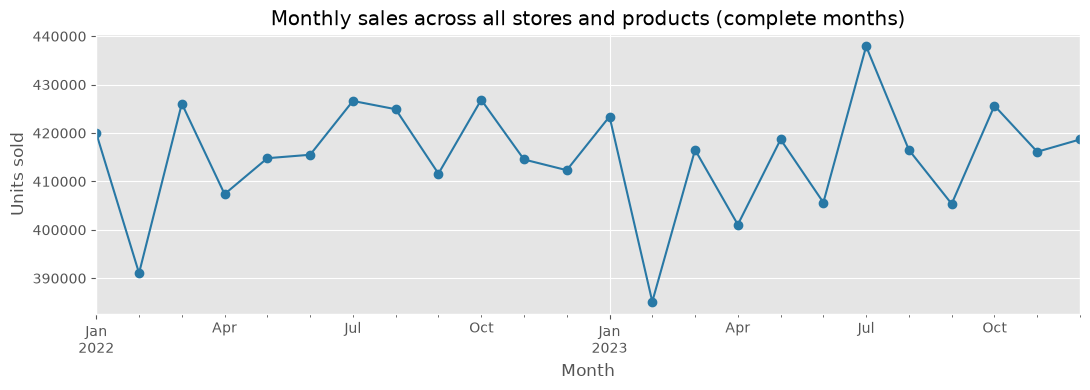

In [19]:
daily_total = clean.groupby("Date")["Units Sold"].sum()
monthly_total = daily_total.resample("MS").sum()
complete_months = monthly_total[monthly_total.index + pd.offsets.MonthEnd(0) <= clean["Date"].max()]
fig, ax = plt.subplots(figsize=(11, 4))
complete_months.plot(ax=ax, marker="o", color="#2878a5")
ax.set(title="Monthly sales across all stores and products (complete months)", xlabel="Month", ylabel="Units sold")
fig.tight_layout()
fig.savefig(figures / "01_monthly_sales.png", dpi=160)
plt.show()

### Observation
Monthly total sales fluctuate without a clear sustained upward or downward trend. July 2023 has the highest total, while February 2023 has the lowest. Month length affects these totals, so average daily sales should also be examined before drawing conclusions.

## 9. Chart: Sales by store

This compares historical total sales, not forecast accuracy or store profitability.

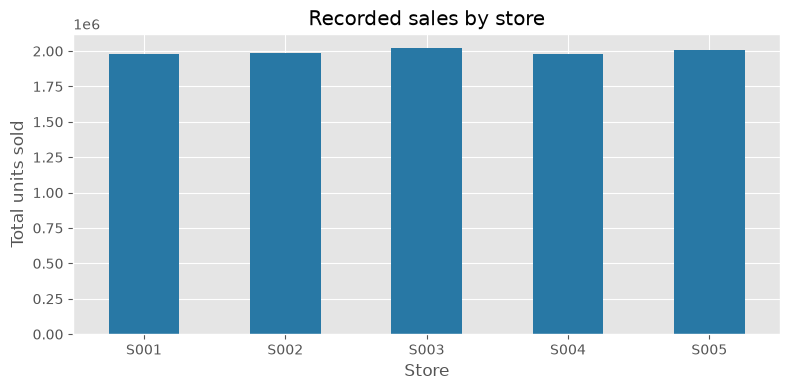

In [20]:
store_sales = clean.groupby("Store ID")["Units Sold"].sum().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
store_sales.plot(kind="bar", ax=ax, color="#2878a5")
ax.set(title="Recorded sales by store", xlabel="Store", ylabel="Total units sold")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figures / "02_store_sales.png", dpi=160)
plt.show()

### Observation
Total recorded sales are similar across the five stores. S003 has the highest total, with relatively small differences between stores. This chart compares units sold, not profitability.

## 10. Chart: Products with highest recorded sales

Product codes are identifiers. We do not invent product names or treat an inconsistent category as a verified product identity.

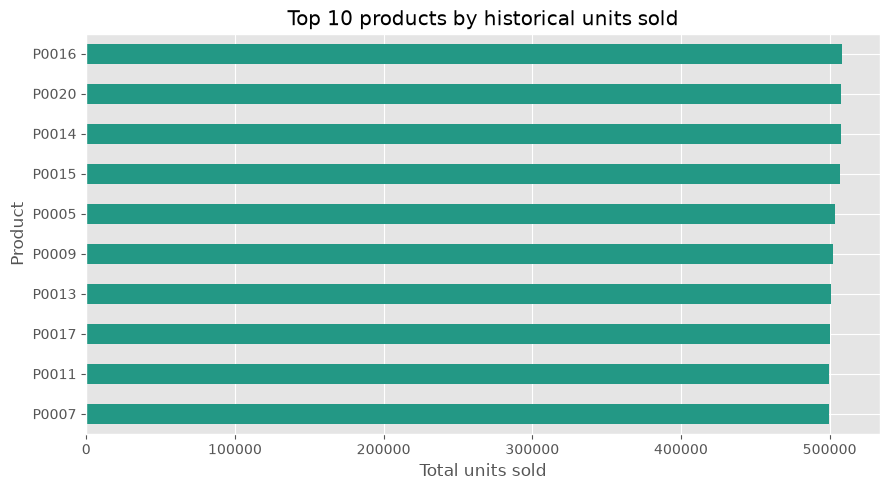

In [11]:
product_sales = clean.groupby("Product ID")["Units Sold"].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
product_sales.plot(kind="barh", ax=ax, color="#239885")
ax.set(title="Top 10 products by historical units sold", xlabel="Total units sold", ylabel="Product")
fig.tight_layout()
fig.savefig(figures / "03_product_sales.png", dpi=160)
plt.show()

### Observation
P0016 has the highest recorded sales across all stores. The top 10 products have similar sales totals, around 500,000
units each. These totals describe historical sales, not future demand.

## 11. Choose any available store and product

Change the two variables below and rerun this cell and the following chart. This does not train a model yet.
Roman Urdu: Yahan apni pasand ka store aur product select karke uski sales history dekhein.

In [27]:
store_id = "S001"
product_id = "P0001"
print("Available stores:", sorted(clean["Store ID"].unique()))
print("Available products:", sorted(clean["Product ID"].unique()))
selected = clean[(clean["Store ID"] == store_id) & (clean["Product ID"] == product_id)].copy()
assert not selected.empty, "Choose an existing store-product pair."
print("Selected:", store_id, product_id, "| Daily records:", len(selected))
print(selected[["Date", "Units Sold", "Inventory Level"]].head().to_string(index=False))

Available stores: ['S001', 'S002', 'S003', 'S004', 'S005']
Available products: ['P0001', 'P0002', 'P0003', 'P0004', 'P0005', 'P0006', 'P0007', 'P0008', 'P0009', 'P0010', 'P0011', 'P0012', 'P0013', 'P0014', 'P0015', 'P0016', 'P0017', 'P0018', 'P0019', 'P0020']
Selected: S001 P0001 | Daily records: 731
      Date  Units Sold  Inventory Level
2022-01-01         127              231
2022-01-02          81              116
2022-01-03           5              154
2022-01-04          58               85
2022-01-05         147              238


### Dataset limitation
The same Product ID appears under different categories. Therefore, a Product ID is treated as a synthetic series identifier, not a verified real-world product. Forecasts demonstrate the workflow; their reliability for real inventory decisions is not established.

## 12. Chart: Selected daily sales and a trailing weekly average

The weekly line smooths past observations for exploration. It is not a future prediction.
Later, model features will use shifted rolling averages so the target day's sale is excluded.

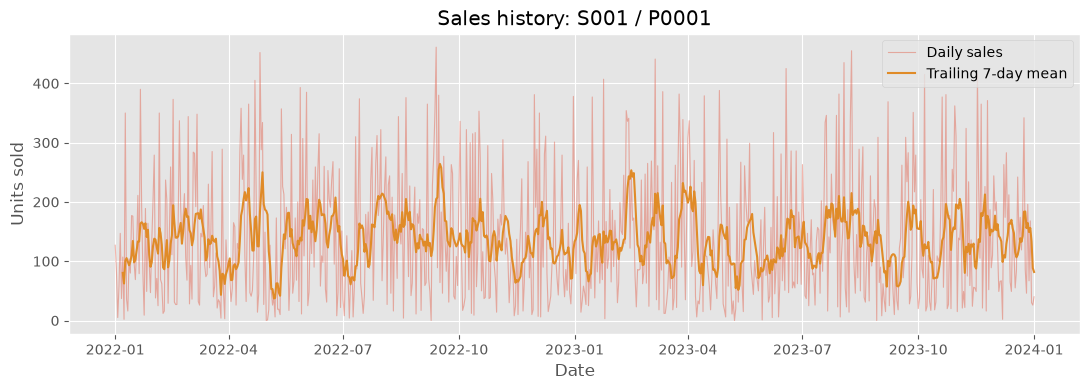

In [28]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(selected["Date"], selected["Units Sold"], alpha=0.4, linewidth=0.8, label="Daily sales")
ax.plot(selected["Date"], selected["Units Sold"].rolling(7).mean(), color="#e08b28", label="Trailing 7-day mean")
ax.set(title=f"Sales history: {store_id} / {product_id}", xlabel="Date", ylabel="Units sold")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "04_selected_sales.png", dpi=160)
plt.show()

### Observation
Daily sales fluctuate substantially. The trailing seven-day mean smooths these fluctuations, but no clear sustained trend is visible. This chart alone does not establish seasonality. Both lines describe
historical sales rather than future predictions.

## 13. Chart: Distribution of selected sales

The histogram shows how often different sales ranges occurred. It does not by itself justify deleting unusually high observations.

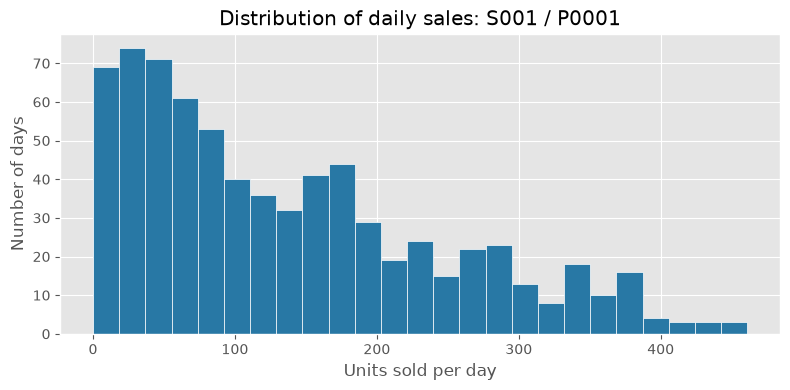

count    731.00
mean     137.31
std      108.19
min        0.00
25%       47.00
50%      109.00
75%      202.00
max      461.00


In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(selected["Units Sold"], bins=25, color="#2878a5", edgecolor="white")
ax.set(title=f"Distribution of daily sales: {store_id} / {product_id}", xlabel="Units sold per day", ylabel="Number of days")
fig.tight_layout()
fig.savefig(figures / "05_sales_distribution.png", dpi=160)
plt.show()
print(selected["Units Sold"].describe().round(2).to_string())

### Observation
Daily sales are right-skewed, with more low-sales days and fewer high-sales days. Mean sales are 137.31 units, while the median is 109 units. Sales range from 0 to 461 units, showing substantial variability. High values are retained because they are not established data errors.

## 14. What have we completed, and what comes next?

We have inspected all combinations, validated essential fields, documented synthetic-data limitations, saved a prepared copy, and created five charts.

**Next notebook:** Build an explicit chronological train/validation/test split. Compare baselines with ARIMA and XGBoost, build features from past values only, and evaluate multiple forecast origins. A model may be weak on this synthetic data; we will report measured results honestly.

Before moving on, explain these four questions in your own words:
1. What is our prediction target?
2. Why does zero missing values not prove realistic data?
3. Why must we keep raw data unchanged?
4. Why does changing inventory affect stock requirements rather than sales forecasts?

No live deployment, new model training, final report or presentation is claimed in this stage.